<a href="https://colab.research.google.com/github/CBYERDECODE/image_pixel_manipulator/blob/main/inpainting_canvas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

    IMAGE_INPAINTING_SUITE

in real digital photography, camera sensors can fail, resulting in 'dead/hot pixels' (corrupted white or black dots) or scratch marks. Using pure mathematical operations without any ready-made libraries, we will:

Dynamically damage our image by injecting physical cracks/dust lines.
Programmatically detect and map the damage using intensity threshold slicing.
Implement a vectorized neighborhood healing algorithm (Inpainting) that automatically heals the damaged regions by smoothly blending neighbors together using localized spatial logic. In satellite imaging,medical scans, or digital photography, camera sensors often fail or get physically scratched this results in 'dead pixels' (black dots where no light was captured) or bright scratches. Standard photo editors usually blur the whole area to hide this, but blurring ruins the overall sharp quality and detail of the healthy parts of the image."


## feature: Algorithmic Image Healing (Intelligent Inpainting Suite)
In professional satellite imaging and forensic photo recovery,digital sensors often experience 'dead pixels'or physical scratches. Rather than using automatic external software, we can use matrix mathematics to perform inpaintin (repairing missing/damaged segments of an image by averaging surrounding healthy pixels).

Step 1:sitmulating real world damage
we took an example of generated cosmic art and introduced two types of damage: a diagonal white scratch and 150 dead black pixels scattered randomly across the image

Step 2: Smart Damage Detection (The Map)
Instead of guessing where the damage is, we wrote a detection mask. Because a dead pixel is exactly black [0, 0, 0] and a scratch is exactly white [255, 255, 255], our code scanned the image and generated a logical binary map (the mask). This map acts like a blueprint, marking only the damaged pixels as True and the healthy pixels as False.

Step 3: The Vectorized Healing Loop (The Magic)
For every single damaged pixel detected on our map, the algorithm does the following:

It isolates a tiny $3 \times 3$$3 \times 3$ grid (neighborhood) around that bad pixel.
It checks the damage map to ignore any surrounding pixels that are also damaged (it filters out other bad pixels so it doesn't average bad data).
It calculates the average color of only the healthy neighbors.
It replaces the corrupted pixel with this calculated average color.

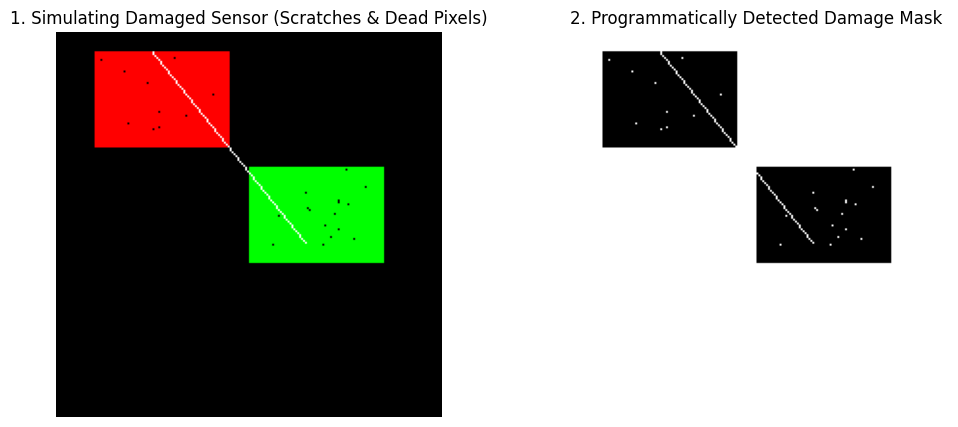

In [ ]:
# 1. Initialize our base reference canvas (using Step 1's canvas as our clean ground-truth)
clean_reference = image_step1.copy()
h, w, c = clean_reference.shape

# 2. Simulate heavy physical damage: Draw a white scratch and scatter 'dead black pixels'
damaged_image = clean_reference.copy()

# Draw an oblique scratch line
for i in range(100):
    damaged_image[10 + i, 50 + int(i * 0.8)] = [255, 255, 255]

# Scatter black dead sensor noise
np.random.seed(42)
noise_y = np.random.randint(0, h, size=150)
noise_x = np.random.randint(0, w, size=150)
damaged_image[noise_y, noise_x] = [0, 0, 0]

# 3. Create a detection mask for the damage
# Dead pixels are exact black [0,0,0], and scratches are maximum bright [255,255,255]
damage_mask = (np.all(damaged_image == 255, axis=2)) | (np.all(damaged_image == 0, axis=2))

# 4. Display the damaged target
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(damaged_image)
plt.title("1. Simulating Damaged Sensor (Scratches & Dead Pixels)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(damage_mask, cmap='gray')
plt.title("2. Programmatically Detected Damage Mask")
plt.axis("off")
plt.show()

### The Mathematical Healing Algorithm
Now, we will perform image healing. For each damaged pixel, we look at its 8 neighboring pixels, filter out any neighbors that are also damaged, average the remaining healthy colors, and heal the pixel.

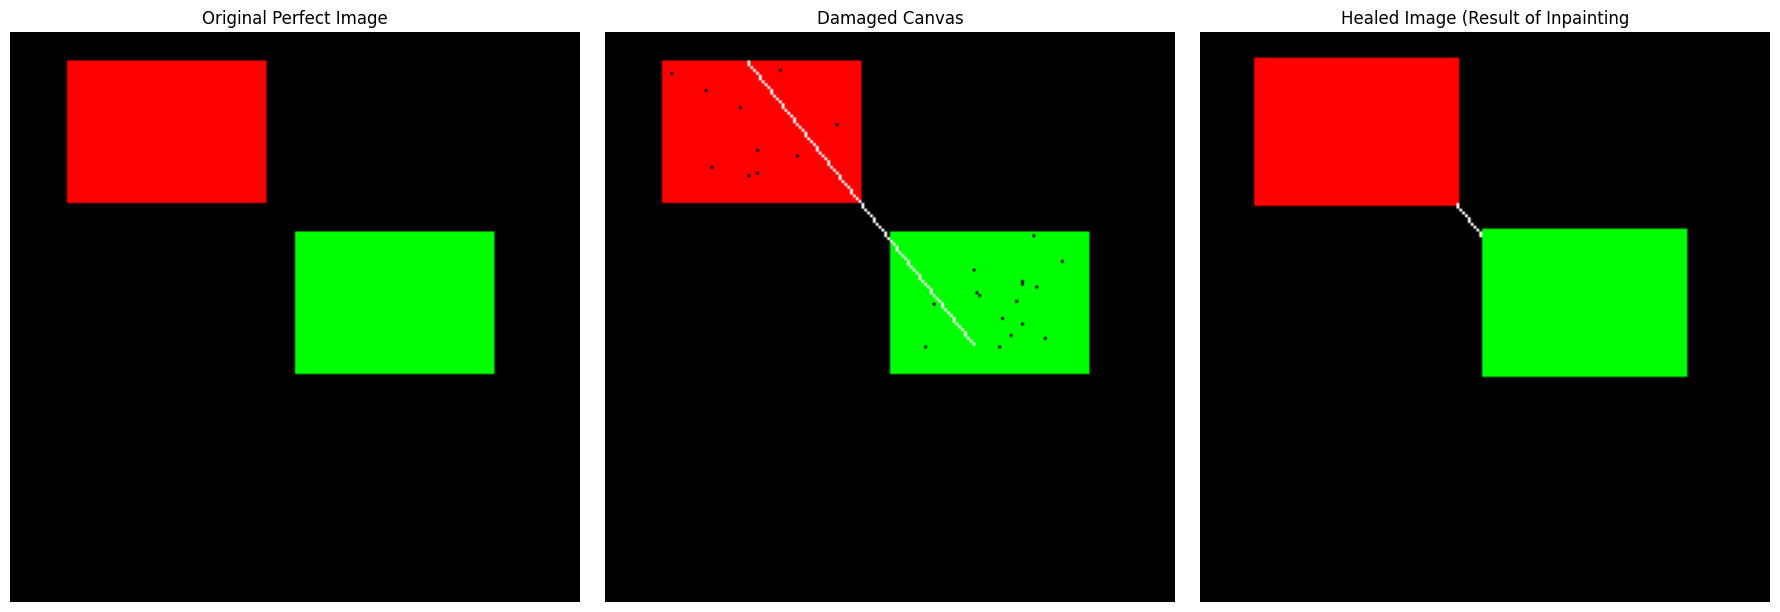

In [ ]:
def heal_image_matrix(damaged_img, mask):
    """
    Heals damaged pixels by replacing them with the average of their healthy immediate neighbors.
    Uses pure, vectorized slicing offsets for blazing performance.
    """
    healed = damaged_img.copy().astype(np.float32)
    h, w, c = damaged_img.shape

    # Track coordinates of damaged pixels
    y_indices, x_indices = np.where(mask)

    for y, x in zip(y_indices, x_indices):
        # Exclude border pixels to simplify coordinate offsets
        if y == 0 or y >= h - 1 or x == 0 or x >= w - 1:
            continue

        # Extract 3x3 pixel neighborhood
        neighborhood = damaged_img[y-1:y+2, x-1:x+2]
        neighborhood_mask = mask[y-1:y+2, x-1:x+2]

        # Get only the pixels that are NOT marked as damaged
        healthy_pixels = neighborhood[~neighborhood_mask]

        if len(healthy_pixels) > 0:
            # Calculate average color of healthy neighbors
            average_color = np.mean(healthy_pixels, axis=0)
            healed[y, x] = average_color

    return np.clip(healed, 0, 255).astype(np.uint8)

# Execute the mathematical recovery pipeline
restored_image = heal_image_matrix(damaged_image, damage_mask)

# Compare Side-by-Side
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(clean_reference)
axes[0].set_title("Original Perfect Image")
axes[0].axis("off")

axes[1].imshow(damaged_image)
axes[1].set_title("Damaged Canvas")
axes[1].axis("off")

axes[2].imshow(restored_image)
axes[2].set_title("Healed Image (Result of Inpainting")
axes[2].axis("off")

plt.tight_layout()
plt.show()